In [62]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import string
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay)
import warnings
warnings.filterwarnings("ignore")

In [63]:
df=pd.read_csv("/Users/nidagallusandeep/Downloads/email_spam_20000.csv")

In [64]:
df.head()

,MessageID,Message,Category
0,MSG10651,"Get a guaranteed loan of ₹10,000 today. Apply ...",spam
1,MSG02042,Your order has been shipped and will arrive on...,ham
2,MSG08669,"Get a guaranteed loan of ₹2,000 today. Apply n...",spam
3,MSG01115,"You are our lucky winner! Receive ₹50,000 by v...",spam
4,MSG13903,Limited time offer: Get 80% discount on shoppi...,spam


In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20000 entries, 0 to 19999
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   MessageID  20000 non-null  object
 1   Message    20000 non-null  object
 2   Category   20000 non-null  object
dtypes: object(3)
memory usage: 468.9+ KB


In [66]:
df.shape

(20000, 3)

In [67]:
df.columns

Index(['MessageID', 'Message', 'Category'], dtype='object')

In [68]:
df.isnull().sum()

MessageID    0
Message      0
Category     0
dtype: int64

In [69]:
df["Category"].value_counts()

Category
spam    10000
ham     10000
Name: count, dtype: int64

In [70]:
df.duplicated().sum()

np.int64(0)

In [71]:
df.describe(include="all")

,MessageID,Message,Category
count,20000,20000,20000
unique,20000,311,2
top,MSG10651,Please find the meeting notes attached. Let me...,spam
freq,1,1026,10000


In [72]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True, inplace=True)

In [73]:
df["Category"].value_counts()

Category
spam    10000
ham     10000
Name: count, dtype: int64

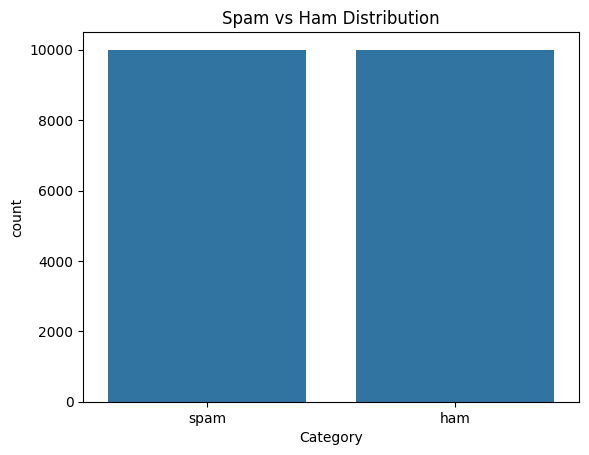

In [74]:
sns.countplot(data=df, x="Category")
plt.title("Spam vs Ham Distribution")
plt.show()

In [75]:
df["Message"] = df["Message"].fillna("")
df["Category"] = df["Category"].str.lower().str.strip()
df.head()

,MessageID,Message,Category
0,MSG10651,"Get a guaranteed loan of ₹10,000 today. Apply ...",spam
1,MSG02042,Your order has been shipped and will arrive on...,ham
2,MSG08669,"Get a guaranteed loan of ₹2,000 today. Apply n...",spam
3,MSG01115,"You are our lucky winner! Receive ₹50,000 by v...",spam
4,MSG13903,Limited time offer: Get 80% discount on shoppi...,spam


# Text Preprocessing

In [76]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\S+", "", text)
    text = re.sub(r"\d+", "", text)
    text = re.sub(r"[^\w\s]", "", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

In [77]:
df["Clean_Message"] = df["Message"].apply(clean_text)
df[["Message", "Clean_Message"]].head()

,Message,Clean_Message
0,"Get a guaranteed loan of ₹10,000 today. Apply ...",get a guaranteed loan of today apply now
1,Your order has been shipped and will arrive on...,your order has been shipped and will arrive on...
2,"Get a guaranteed loan of ₹2,000 today. Apply n...",get a guaranteed loan of today apply now
3,"You are our lucky winner! Receive ₹50,000 by v...",you are our lucky winner receive by visiting
4,Limited time offer: Get 80% discount on shoppi...,limited time offer get discount on shopping visit


# Separate X and y

In [78]:
X = df["Clean_Message"]
y = df["Category"]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (20000,)
y shape: (20000,)


# Train-Test Split

In [79]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.20,random_state=42,stratify=y)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (16000,)
X_test: (4000,)
y_train: (16000,)
y_test: (4000,)


# Build Pipeline using TF-IDF and Naive Bayes

In [80]:
model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=5000,
        ngram_range=(1, 2)
    )),
    ("model", MultinomialNB())
])

In [81]:
model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidf', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[<U4](2,)","['ham','spam']"
,"stop_words stop_words: {'english'}, list, default=NoneIf a string, it is passed to _check_stop_list and the appropriate stoplist is returned. 'english' is currently the only supported stringvalue.There are several known issues with 'english' and you shouldconsider an alternative (see :ref:`stop_words`).If a list, that list is assumed to contain stop words, all of whichwill be removed from the resulting tokens.Only applies if ``analyzer == 'word'``.If None, no stop words will be used. In this case, setting `max_df`to a higher value, such as in the range (0.7, 1.0), can automatically detectand filter stop words based on intra corpus document frequency of terms.",'english'
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"max_features max_features: int, default=NoneIf not None, build a vocabulary that only consider the top`max_features` ordered by term frequency across the corpus.Otherwise, all features are used.This parameter is ignored if vocabulary is not None.",5000
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'


# Make Predictions

In [82]:
y_pred=model.predict(X_test)
print(y_pred[:10])

['spam' 'ham' 'ham' 'spam' 'ham' 'ham' 'spam' 'ham' 'spam' 'spam']


# Classification Metrics

In [83]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred, pos_label="spam"))
print("Recall:", recall_score(y_test, y_pred, pos_label="spam"))
print("F1 Score:", f1_score(y_test, y_pred, pos_label="spam"))

Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0


# Classification Report

In [84]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

         ham       1.00      1.00      1.00      2000
        spam       1.00      1.00      1.00      2000

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000



# Confusion Matrix

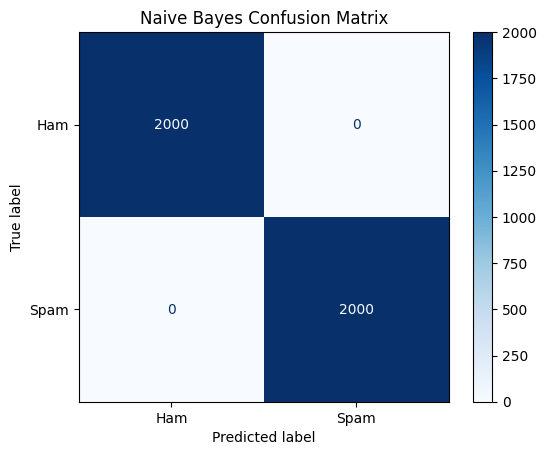

In [85]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["ham", "spam"])

display = ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Ham", "Spam"])
display.plot(cmap="Blues")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

# Hyperparameter Tuning using RandomizedSearchCV

In [86]:
param_grid = {
    "tfidf__max_features": [3000, 5000, 7000],
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "model__alpha": [0.1, 0.5, 1.0, 2.0]
}

In [87]:
random_search = RandomizedSearchCV(
    estimator=model,
    param_distributions=param_grid,
    n_iter=5,
    cv=3,
    scoring="f1",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 3 folds for each of 5 candidates, totalling 15 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...inomialNB())])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__alpha': [0.1, 0.5, ...], 'tfidf__max_features': [3000, 5000, ...], 'tfidf__ngram_range': [(1, ...), (1, ...)]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",5
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",3
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected 

# Best Parameters

In [88]:
print("Best Parameters:", random_search.best_params_)
print("Best F1 Score:", random_search.best_score_)

Best Parameters: {'tfidf__ngram_range': (1, 1), 'tfidf__max_features': 5000, 'model__alpha': 0.5}
Best F1 Score: nan


# Evaluate Tuned Model

In [89]:
best_model = random_search.best_estimator_
y_pred_tuned = best_model.predict(X_test)
print(classification_report(y_test, y_pred_tuned))

              precision    recall  f1-score   support

         ham       1.00      1.00      1.00      2000
        spam       1.00      1.00      1.00      2000

    accuracy                           1.00      4000
   macro avg       1.00      1.00      1.00      4000
weighted avg       1.00      1.00      1.00      4000



In [90]:
print("Original Model Accuracy:",
      accuracy_score(y_test, y_pred))
print("Tuned Model Accuracy:",
      accuracy_score(y_test, y_pred_tuned))

Original Model Accuracy: 1.0
Tuned Model Accuracy: 1.0


In [91]:
new_messages = [
    "Congratulations! You won a free laptop. Claim now!",
    "Hi, can we meet tomorrow at 10 AM?",
    "Get 80 percent discount. Click here to claim your offer.",
    "Please send me the project report."
]

predictions = best_model.predict(new_messages)

for message, prediction in zip(new_messages, predictions):
    print("Message:", message)
    print("Prediction:", prediction)
    print("----------------------------")

Message: Congratulations! You won a free laptop. Claim now!
Prediction: spam
----------------------------
Message: Hi, can we meet tomorrow at 10 AM?
Prediction: ham
----------------------------
Message: Get 80 percent discount. Click here to claim your offer.
Prediction: spam
----------------------------
Message: Please send me the project report.
Prediction: ham
----------------------------


In [92]:
import joblib
joblib.dump(best_model, "email_spam_naive_bayes.pkl")
print("Model saved successfully!")

Model saved successfully!


In [93]:
loaded_model = joblib.load("email_spam_naive_bayes.pkl")
print("Model loaded successfully!")

Model loaded successfully!


In [94]:
test_message = ["You have won a free gift voucher. Claim now!"]
result = loaded_model.predict(test_message)
print("Email Category:", result[0])

Email Category: spam
